# 03 Personalization (H2) and heterogeneity (H3)

H2 asks: for a customer who bought from only one category last year, does getting the email that **matches** that category work better than getting the other email?

H3 asks: does the effect of emailing differ for new customers, and for recent buyers? Only these two interactions are confirmatory.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from helpers import load_data, diff_in_means, holm

df = load_data()
df["mens_only"] = (df["past_category"] == "mens only").astype(int)

## H2: Is personalization worth it? (confirmatory)

Sample: customers who bought only mens or only womens items last year and got an email.

matched = 1 if a mens-only buyer got the Mens email, or a womens-only buyer got the Womens email.

Model: visit ~ matched + mens_only, HC2 SEs. The `mens_only` dummy compares customers only within their own past-category group. Inside each group the email type was random, so the `matched` coefficient is causal.

In [2]:
single = df[(df["past_category"] != "both") & (df["any_email"] == 1)].copy()
single["matched"] = 0
single.loc[(single["mens_only"] == 1) & (single["mens_email"] == 1), "matched"] = 1
single.loc[(single["mens_only"] == 0) & (single["womens_email"] == 1), "matched"] = 1

print("Customers in the H2 sample:", len(single))
print(pd.crosstab(single["past_category"], single["segment"]))
print()
visit_by_matched = single.groupby("matched")["visit"].mean()
print(visit_by_matched.round(4))

Customers in the H2 sample: 38395
segment        Mens E-Mail  Womens E-Mail
past_category                            
mens only             9558           9622
womens only           9568           9647

matched
0    0.1386
1    0.1694
Name: visit, dtype: float64


In [3]:
h2_rows = []
for outcome in ["visit", "conversion", "spend"]:
    model = smf.ols(outcome + " ~ matched + mens_only", data=single).fit(cov_type="HC2")
    coef = model.params["matched"]
    se = model.bse["matched"]
    p = model.pvalues["matched"]
    role = "secondary"
    if outcome == "visit":
        role = "confirmatory"
    h2_rows.append([outcome, role, coef, se, coef - 1.96 * se, coef + 1.96 * se, p])
    print(outcome, " matched coef:", round(coef, 4), " SE:", round(se, 4), " p:", round(p, 5))

h2 = pd.DataFrame(h2_rows, columns=["outcome", "role", "matched_coef", "se", "ci_low", "ci_high", "p_value"])
h2 = h2.round(6)
h2.to_csv("results/personalization_test.csv", index=False)
h2

visit  matched coef: 0.0307  SE: 0.0037  p: 0.0
conversion  matched coef: 0.0024  SE: 0.001  p: 0.01724
spend  matched coef: 0.21  SE: 0.1601  p: 0.18959


,outcome,role,matched_coef,se,ci_low,ci_high,p_value
0,visit,confirmatory,0.030716,0.003679,0.023506,0.037927,0.000000
1,conversion,secondary,0.002382,0.001000,0.000422,0.004343,0.017243
2,spend,secondary,0.209972,0.160066,-0.103757,0.523702,0.189592


In [4]:
model_visit = smf.ols("visit ~ matched + mens_only", data=single).fit(cov_type="HC2")
print(model_visit.summary())

                            OLS Regression Results                            
Dep. Variable:                  visit   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     69.68
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           6.20e-31
Time:                        17:04:20   Log-Likelihood:                -15288.
No. Observations:               38395   AIC:                         3.058e+04
Df Residuals:                   38392   BIC:                         3.061e+04
Df Model:                           2                                         
Covariance Type:                  HC2                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1527      0.003     46.806      0.0

## Descriptive: visit uplift of each email in each buyer group

Not a test. For each buyer group, the visit rate of each email arm minus the control visit rate in the same group, with a 95% CI.

In [5]:
groups = ["mens only", "womens only", "both"]
desc_rows = []
for group in groups:
    part = df[df["past_category"] == group]
    group_control = part[part["segment"] == "No E-Mail"]
    for arm_name in ["Mens E-Mail", "Womens E-Mail"]:
        group_treat = part[part["segment"] == arm_name]
        diff, se = diff_in_means(group_treat["visit"], group_control["visit"])
        desc_rows.append([group, arm_name, len(group_treat), len(group_control), group_control["visit"].mean(), diff, se, diff - 1.96 * se, diff + 1.96 * se])

uplift_by_group = pd.DataFrame(desc_rows, columns=["buyer_group", "email", "n_treat", "n_control", "control_visit_rate", "uplift", "se", "ci_low", "ci_high"])
uplift_by_group = uplift_by_group.round(5)
uplift_by_group.to_csv("results/visit_uplift_by_buyer_group.csv", index=False)
uplift_by_group

,buyer_group,email,n_treat,n_control,control_visit_rate,uplift,se,ci_low,ci_high
0,mens only,Mens E-Mail,9558,9638,0.09981,0.06916,0.00490,0.05955,0.07876
1,mens only,Womens E-Mail,9622,9638,0.09981,0.01108,0.00442,0.00241,0.01975
2,womens only,Mens E-Mail,9568,9519,0.09581,0.07058,0.00486,0.06106,0.08010
3,womens only,Womens E-Mail,9647,9519,0.09581,0.07399,0.00487,0.06444,0.08353
4,both,Mens E-Mail,2181,2149,0.18055,0.13444,0.01296,0.10905,0.15984
5,both,Womens E-Mail,2118,2149,0.18055,0.07110,0.01256,0.04648,0.09573


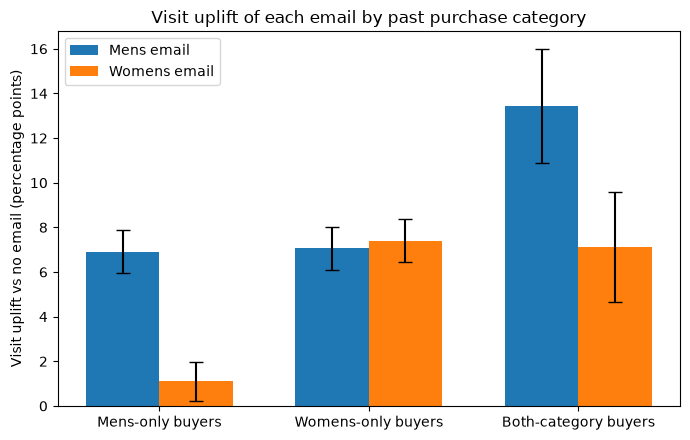

In [6]:
mens_part = uplift_by_group[uplift_by_group["email"] == "Mens E-Mail"]
womens_part = uplift_by_group[uplift_by_group["email"] == "Womens E-Mail"]
positions = np.arange(len(groups))
width = 0.35

mens_err = [mens_part["uplift"] * 100 - mens_part["ci_low"] * 100, mens_part["ci_high"] * 100 - mens_part["uplift"] * 100]
womens_err = [womens_part["uplift"] * 100 - womens_part["ci_low"] * 100, womens_part["ci_high"] * 100 - womens_part["uplift"] * 100]

plt.figure(figsize=(7, 4.5))
plt.bar(positions - width / 2, mens_part["uplift"] * 100, width, yerr=mens_err, capsize=5, label="Mens email")
plt.bar(positions + width / 2, womens_part["uplift"] * 100, width, yerr=womens_err, capsize=5, label="Womens email")
plt.xticks(positions, ["Mens-only buyers", "Womens-only buyers", "Both-category buyers"])
plt.ylabel("Visit uplift vs no email (percentage points)")
plt.title("Visit uplift of each email by past purchase category")
plt.legend()
plt.tight_layout()
plt.savefig("figures/uplift_by_buyer_group.png", dpi=150)
plt.show()

## H3: Heterogeneity (confirmatory, two interactions)

Full sample. email = 1 for Mens or Womens email, 0 for no email.

- Model A: visit ~ email + newbie + email:newbie
- Model B: visit ~ email + recent + email:recent, where recent = 1 if the last purchase was 6 months ago or less.

The interaction coefficient is the difference in the email effect between the two groups. Holm correction across the two tests.

In [7]:
model_newbie = smf.ols("visit ~ any_email + newbie + any_email:newbie", data=df).fit(cov_type="HC2")
model_recent = smf.ols("visit ~ any_email + recent + any_email:recent", data=df).fit(cov_type="HC2")

print(model_newbie.summary().tables[1])
print()
print(model_recent.summary().tables[1])

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.1337      0.003     40.471      0.000       0.127       0.140
any_email            0.0590      0.004     13.808      0.000       0.051       0.067
newbie              -0.0549      0.004    -13.048      0.000      -0.063      -0.047
any_email:newbie     0.0038      0.006      0.693      0.488      -0.007       0.015

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0805      0.003     28.233      0.000       0.075       0.086
any_email            0.0595      0.004     15.520      0.000       0.052       0.067
recent               0.0448      0.004     10.818      0.000       0.037       0.053
any_email:recent     0.0025      0.005      0.457      0.648    

In [8]:
h3_rows = []
for name, model, term in [["newbie", model_newbie, "any_email:newbie"], ["recent", model_recent, "any_email:recent"]]:
    base_effect = model.params["any_email"]
    inter = model.params[term]
    se = model.bse[term]
    p = model.pvalues[term]
    h3_rows.append([name, base_effect, base_effect + inter, inter, se, inter - 1.96 * se, inter + 1.96 * se, p])

h3 = pd.DataFrame(h3_rows, columns=["moderator", "effect_when_0", "effect_when_1", "interaction", "se", "ci_low", "ci_high", "p_value"])
h3["holm_p_value"] = holm(h3["p_value"].values)
h3 = h3.round(6)
h3.to_csv("results/heterogeneity_tests.csv", index=False)
h3

,moderator,effect_when_0,effect_when_1,interaction,se,ci_low,ci_high,p_value,holm_p_value
0,newbie,0.058975,0.062816,0.003841,0.005541,-0.007018,0.014701,0.488119,0.976237
1,recent,0.059533,0.062031,0.002499,0.005472,-0.008226,0.013223,0.647933,0.976237


In [9]:
for moderator in ["newbie", "recent"]:
    for value in [0, 1]:
        part = df[df[moderator] == value]
        group_control = part[part["any_email"] == 0]
        group_treat = part[part["any_email"] == 1]
        diff, se = diff_in_means(group_treat["visit"], group_control["visit"])
        print(moderator, "=", value, " control visit rate:", round(group_control["visit"].mean(), 4), " email effect:", round(diff, 4), " SE:", round(se, 4))

newbie = 0  control visit rate: 0.1337  email effect: 0.059  SE: 0.0043
newbie = 1  control visit rate: 0.0788  email effect: 0.0628  SE: 0.0035
recent = 0  control visit rate: 0.0805  email effect: 0.0595  SE: 0.0038
recent = 1  control visit rate: 0.1253  email effect: 0.062  SE: 0.0039


## Summary

**H2, personalization (confirmatory, visit):** among single-category buyers who got an email, getting the matching email raised the visit rate by **3.1 percentage points** (95% CI 2.4 to 3.8, p < 0.001), from 13.9% to 16.9%. Personalization works on visits.

**Secondary:** matching raised conversion by 0.24 points (p = 0.017). The effect on spend was +$0.21 per customer but not significant (95% CI −$0.10 to $0.52, p = 0.19).

**What the descriptive chart adds (not a test):** the matched effect is not symmetric.

- Mens-only buyers: the Mens email lifts visits by 6.9 points, the Womens email by only 1.1 points.
- Womens-only buyers: both emails work about equally (Mens 7.1, Womens 7.4 points).
- Both-category buyers: the Mens email lifts visits by 13.4 points, the Womens email by 7.1.

So the H2 coefficient is an average of a big matching gain for men's buyers and almost none for women's buyers. In plain words, the Mens email works for everyone, while the Womens email does not reach men's buyers. Any claim that personalization matters for one group but not the other would be **Exploratory**, because the plan tested only the pooled coefficient.

**H3, heterogeneity (confirmatory):** the email effect on visits is almost the same for new and old customers (+6.3 vs +5.9 points, interaction p = 0.49) and for recent and older buyers (+6.2 vs +6.0 points, interaction p = 0.65). Holm-adjusted p = 0.98 for both. There is no evidence that the absolute uplift differs along these two lines, even though new customers and older buyers have lower base visit rates.